# 05 · Galerias de Faces e busca por semelhança

**Pré-requisito:** notebooks 00 a 04 (as imagens da FEI já estão no `faces_db`).

As partes 1 a 3 são um **passo a passo**: todas as células já estão preenchidas. Rode uma por vez e observe o resultado. No final ficam os **Exercícios 8 e 9**, para você fazer seguindo os exemplos.

- **Parte 1:** paginação com `skip` e `limit`.
- **Parte 2:** o app **Galerias de Faces**, com filtros, páginas e envio de fotos.
- **Parte 3:** banco de dados + machine learning: encontrar a face mais parecida.

> **Sobre os dados:** As imagens da FEI são liberadas só para pesquisa, sem redistribuição. Por isso o app roda **só no seu computador**: não publique a galeria na internet.

In [ ]:
%pip install -q pymongo python-dotenv pillow numpy matplotlib requests streamlit

---
## Conexão com o banco de imagens

A célula lê o `.env`, conecta e abre o GridFS do banco `faces_db`, preenchido no notebook 04.

In [1]:
import os, io, gridfs
from dotenv import load_dotenv
from pymongo import MongoClient
from PIL import Image
from IPython.display import display

load_dotenv()
client = MongoClient(os.environ["MONGO_URI"])
db = client["faces_db"]
fs = gridfs.GridFS(db)
print(db.fs.files.count_documents({}), "imagens no banco")

200 imagens no banco


---
## Parte 1 · Paginação: mostrar um pedaço de cada vez

Uma galeria não mostra centenas de fotos de uma vez: mostra **páginas**. No MongoDB isso é feito com dois comandos no `find`:

| Comando | O que faz | Analogia |
|---|---|---|
| `.skip(n)` | pula os `n` primeiros | folhear o livro até a página certa |
| `.limit(n)` | devolve no máximo `n` | ler só aquela página |

Com `por_pagina` itens por página, a página `p` começa depois de `(p - 1) * por_pagina` itens. O `.sort` garante que a ordem seja sempre a mesma.

In [2]:
por_pagina = 6

for pagina in [1, 2]:
    pular = (pagina - 1) * por_pagina
    nomes = [a["filename"] for a in db.fs.files.find({}, {"filename": 1})
                                     .sort("metadata.pessoa", 1).skip(pular).limit(por_pagina)]
    print(f"Página {pagina} (pula {pular}):", nomes)

Página 1 (pula 0): ['1a.jpg', '1b.jpg', '2b.jpg', '2a.jpg', '3b.jpg', '3a.jpg']
Página 2 (pula 6): ['4a.jpg', '4b.jpg', '5b.jpg', '5a.jpg', '6b.jpg', '6a.jpg']


**Quantas páginas?** Total de imagens dividido por `por_pagina`, arredondando **para cima** (a última página pode ficar incompleta):

In [3]:
import math

total = db.fs.files.count_documents({})
paginas = math.ceil(total / por_pagina)
print(f"{total} imagens / {por_pagina} por página = {paginas} páginas")

200 imagens / 6 por página = 34 páginas


A paginação também funciona **junto com um filtro**: primeiro o `find` filtra, depois o `skip`/`limit` recorta.

In [4]:
filtro = {"metadata.expressao": "sorrindo"}
print("Sorrindo:", db.fs.files.count_documents(filtro), "imagens")

for a in db.fs.files.find(filtro, {"filename": 1}).sort("metadata.pessoa", 1).skip(0).limit(5):
    print(a["filename"])

Sorrindo: 100 imagens
1b.jpg
2b.jpg
3b.jpg
4b.jpg
5b.jpg


---
## Parte 2 · O app Galerias de Faces

O app fica na pasta `galeria`. A célula abaixo cria a pasta e o arquivo de segredos do Streamlit a partir do seu `.env`, como no notebook 03.

In [5]:
os.makedirs("galeria/.streamlit", exist_ok=True)
with open("galeria/.streamlit/secrets.toml", "w", encoding="utf-8") as f:
    f.write(f'MONGO_URI = "{os.environ["MONGO_URI"]}"\n')
print("Criados: galeria/  e  galeria/.streamlit/secrets.toml")

Criados: galeria/  e  galeria/.streamlit/secrets.toml


A próxima célula grava o app em `galeria/app.py`. Ele tem três blocos:

1. **Filtros:** um `selectbox` de expressão e um `number_input` com o número da pessoa (0 = todas). Os dois montam o dicionário `filtro`, usando os campos `metadata.expressao` e `metadata.pessoa`.
2. **Paginação e grade:** a mesma conta da Parte 1 (`count_documents`, `skip`, `limit`). As imagens vão para `st.columns(4)`: a imagem `i` cai na coluna `i % 4`, então a grade preenche da esquerda para a direita.
3. **Envio de foto:** `st.file_uploader` recebe o arquivo; se o nome ainda não existe (`fs.exists`), grava com `fs.put` e os metadados escolhidos.

In [6]:
%%writefile galeria/app.py
import io
import gridfs
import streamlit as st
from PIL import Image
from pymongo import MongoClient

st.set_page_config(page_title="Galerias de Faces", layout="wide")

@st.cache_resource
def conectar():
    db = MongoClient(st.secrets["MONGO_URI"])["faces_db"]
    return db, gridfs.GridFS(db)

db, fs = conectar()
st.title("Galerias de Faces")

# 1. Filtros
c1, c2 = st.columns(2)
expr = c1.selectbox("Expressão", ["todas", "neutra", "sorrindo"])
pessoa = c2.number_input("Número da pessoa (0 = todas)", min_value=0, step=1)
filtro = {}
if expr != "todas":
    filtro["metadata.expressao"] = expr
if pessoa:
    filtro["metadata.pessoa"] = int(pessoa)

# 2. Paginação e grade
por_pagina = 20
total = db.fs.files.count_documents(filtro)
paginas = max(1, (total + por_pagina - 1) // por_pagina)
pagina = st.number_input(f"Página (1 a {paginas})", min_value=1, max_value=paginas, value=1)
st.caption(f"{total} imagens encontradas")

arquivos = (db.fs.files.find(filtro).sort("metadata.pessoa", 1)
            .skip((pagina - 1) * por_pagina).limit(por_pagina))
colunas = st.columns(4)
for i, info in enumerate(arquivos):
    img = Image.open(io.BytesIO(fs.get(info["_id"]).read()))
    colunas[i % 4].image(img, caption=info["filename"])

# 3. Upload
st.divider()
st.subheader("Enviar nova foto")
with st.form("upload", clear_on_submit=True):
    arquivo = st.file_uploader("Imagem JPG", type=["jpg", "jpeg"])
    num = st.number_input("Número da pessoa", min_value=1, step=1)
    nova_expr = st.selectbox("Expressão da foto", ["neutra", "sorrindo"])
    if st.form_submit_button("Enviar") and arquivo:
        if fs.exists(filename=arquivo.name):
            st.warning(f"Já existe uma imagem chamada {arquivo.name}.")
        else:
            dados = arquivo.getvalue()
            largura, altura = Image.open(io.BytesIO(dados)).size
            fs.put(dados, filename=arquivo.name, metadata={
                "pessoa": int(num), "expressao": nova_expr,
                "largura": largura, "altura": altura, "origem": "upload"})
            st.success(f"{arquivo.name} enviada!")

Overwriting galeria/app.py


### Rodar o app

A célula abaixo escreve os dois comandos com o caminho completo da pasta `galeria` e do seu Python. Depois: **Terminal → New Terminal** → cole as duas linhas, uma por vez. O app abre em `http://localhost:8501`. Para parar: **Ctrl+C**.

No app, teste: filtre por “sorrindo”, digite o número de uma pessoa, troque de página e envie uma foto.

In [7]:
import sys

pasta = os.path.abspath("galeria")
print("Copie e cole no terminal (PowerShell), uma linha por vez:\n")
print(f'cd "{pasta}"')
print(f'& "{sys.executable}" -m streamlit run app.py')

Copie e cole no terminal (PowerShell), uma linha por vez:

cd "c:\Users\Rafael\Desktop\AULAS\SENAI\2026_LAABD\Aula 13 - NoSQL - MongoDB - Bancos Documento e Chave Valor\aula_mongodb_notebooks_local\galeria"
& "c:\Users\Rafael\AppData\Local\Programs\Python\Python312\python.exe" -m streamlit run app.py


---
## Parte 3 · Qual é a face mais parecida?

Juntando banco de dados e machine learning: dada uma foto, encontrar no banco a face mais parecida com ela.

1. **Vetorizar:** cada imagem vira uma lista de números. Convertemos para tons de cinza (`"L"`), reduzimos para 64 × 64 e dividimos por 255: são **4096 valores entre 0 e 1**.
2. **Guardar os vetores** numa coleção comum, `vetores`, para não recalcular a cada busca.
3. **Comparar:** a **distância euclidiana** entre dois vetores mede o quanto as imagens diferem. A menor distância é a face mais parecida.

Veja como fica o vetor de uma imagem:

1a.jpg -> (4096,) valores. Os 5 primeiros: [0.74509805 0.74509805 0.7411765  0.7411765  0.7411765 ]


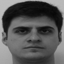

In [8]:
import numpy as np

arq = fs.find_one({"filename": "1a.jpg"})
img = Image.open(io.BytesIO(arq.read())).convert("L").resize((64, 64))
vetor = np.asarray(img, dtype=np.float32).ravel() / 255.0

print(arq.filename, "->", vetor.shape, "valores. Os 5 primeiros:", vetor[:5])
display(img)

### Guardar os vetores no banco

Um documento por imagem: `file_id` (liga ao `fs.files`), `filename` e `vetor`. O MongoDB não guarda arrays do NumPy, então convertemos com `.tolist()`. Apagamos a coleção antes, para poder rodar a célula de novo sem duplicar.

In [9]:
vetores = db["vetores"]
vetores.drop()

for info in db.fs.files.find({}, {"filename": 1}):
    img = Image.open(io.BytesIO(fs.get(info["_id"]).read())).convert("L").resize((64, 64))
    v = np.asarray(img, dtype=np.float32).ravel() / 255.0
    vetores.insert_one({"file_id": info["_id"], "filename": info["filename"], "vetor": v.tolist()})

print(vetores.count_documents({}), "vetores gravados")

200 vetores gravados


### Buscar a mais parecida

Vamos usar a **`1b.jpg`** (pessoa 1 sorrindo) como consulta. Montamos uma matriz com todos os vetores do banco (menos o da própria foto) e calculamos, de uma vez, a distância de cada um até o vetor da consulta com `np.linalg.norm(..., axis=1)`. O `argmin` diz qual é a menor.

O ideal seria encontrar a **`1a.jpg`**: a mesma pessoa, com expressão neutra. Como comparamos pixel a pixel, nem sempre isso acontece: luz, posição e o próprio sorriso mudam muitos pixels. No Exercício 9 você vai medir quantas vezes a busca acerta.

Mais parecida com 1b.jpg: 1a.jpg (distância 4.49)


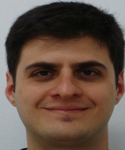

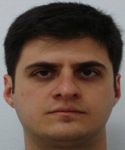

In [10]:
consulta = "1b.jpg"
alvo = np.array(vetores.find_one({"filename": consulta})["vetor"], dtype=np.float32)

docs = list(vetores.find({"filename": {"$ne": consulta}}, {"filename": 1, "file_id": 1, "vetor": 1}))
matriz = np.array([d["vetor"] for d in docs], dtype=np.float32)
distancias = np.linalg.norm(matriz - alvo, axis=1)

i = int(distancias.argmin())
print(f"Mais parecida com {consulta}: {docs[i]['filename']} (distância {distancias[i]:.2f})")

for nome in [consulta, docs[i]["filename"]]:
    display(Image.open(io.BytesIO(fs.find_one({"filename": nome}).read())).resize((125, 150)))

---
## Agora é a sua vez · Exercícios 8 e 9

Use os exemplos acima como modelo.

### Exercício 8 · Melhorando a galeria
Edite o app (a célula `%%writefile galeria/app.py` da Parte 2, ou direto o arquivo `galeria/app.py` no VS Code) e rode de novo:

1. Troque a grade para **5 colunas** e **15 imagens por página**.
2. Mude a legenda de cada foto para algo como **“Pessoa 12 · sorrindo”**, usando os metadados (`info["metadata"]`).
3. Logo abaixo do título, mostre dois `st.metric`: **total de imagens no banco** e **quantidade de pessoas diferentes** (`db.fs.files.distinct("metadata.pessoa")`).

Mostre ao professor funcionando, ou envie um print da tela.

In [ ]:
# Exercício 8: escreva aqui o seu %%writefile galeria/app.py (ou edite o arquivo direto)
# seu código aqui

### Exercício 9 · A busca acerta?
Na Parte 3, a `1b.jpg` encontrou a `1a.jpg`. Será que funciona sempre?

1. Para cada pessoa de **1 a 10**, use a foto **sorrindo** (`"<n>b.jpg"`) como consulta, sem compará-la com ela mesma.
2. Considere **acerto** quando a mais parecida for a foto neutra da **mesma pessoa** (`"<n>a.jpg"`).
3. Mostre o resultado de cada consulta e, no final, quantos acertos de 10.

*Dica:* é o código da Parte 3 dentro de um `for n in range(1, 11):`.

In [ ]:
# Exercício 9
# seu código aqui

---
## Checklist de entrega
- [ ] Coleção `escola.alunos` no seu MongoDB (Exercícios 1 e 2)
- [ ] App “Secretaria online” rodando (notebook 03)
- [ ] Faces da FEI no GridFS, sem duplicatas e com metadados (notebook 04)
- [ ] Consultas no GridFS (Exercícios 5, 6 e 7)
- [ ] App “Galerias de Faces” melhorado, rodando no seu computador (Exercício 8)
- [ ] Teste da busca por semelhança (Exercício 9)